# Broiler validation: step-by-step
Open this notebook in the remote VS Code workspace and select a Python kernel running there. Copy your FlockLabel export to the remote environment, set its path below, then select **Run All**. Paths refer to the remote machine, not your local computer. This notebook previews each processing stage on one frame, runs the actual pipeline on every exported clip, evaluates the results, and creates a video with ground-truth and estimated boxes. Processing long clips can take time.

The export must contain `test_videos/metadata.csv` (`video_name`), the videos it lists, `ground_truth/events.csv` (`video_name`, optionally `pixel_to_cm`), and `ground_truth/gt_boxes.csv` (`video_name`, `frame_idx`, `x`, `y`, `w`, `h`, `weight_kg`, `event_id`). Boxes are pixel coordinates in `(x, y, width, height)` format. Set the offset to 1 if your ground truth numbers the first frame 0; the pipeline numbers it 1.

In [8]:
!git clone https://github.com/Akintanoreofe/BroilerWeightEstimation.git ~/BroilerWeightEstimation

fatal: destination path '/Users/akintanoreofeoluwa/BroilerWeightEstimation' already exists and is not an empty directory.


In [27]:
from pathlib import Path

# Leave as None for automatic discovery; otherwise use the remote repository folder, not run_eval.py.
REPO_ROOT = Path.home() / "BroilerWeightEstimation" # e.gsrc/validation_walkthrough.ipynb)
cwd = Path.cwd().resolve()
if REPO_ROOT is None:
    ROOT = next((p for p in (cwd, *cwd.parents) if (p / 'src' / 'run_eval.py').is_file()), None)
    if ROOT is None:
        raise FileNotFoundError(f'Cannot find the repository from {cwd}. Set REPO_ROOT to the folder containing src/run_eval.py, then rerun this cell.')
else:
    ROOT = Path(REPO_ROOT).expanduser().resolve()
    if not (ROOT / 'src' / 'run_eval.py').is_file():
        raise FileNotFoundError(f'REPO_ROOT does not contain src/run_eval.py: {ROOT}')

# Set this to your export on the remote machine, relative to ROOT or an absolute path.
EXPORT_DIR = (ROOT / Path('/Users/akintanoreofeoluwa/Downloads/eval_2026-11-14_16444').expanduser()).resolve()
RESULTS_DIR = EXPORT_DIR / 'results'
GT_FRAME_OFFSET = 0  # 0 for one-based GT frame numbers; 1 for zero-based
IOU_THRESHOLD = 0.3
PREVIEW_VIDEO = None  # None selects the first video; otherwise use its exact filename
PREVIEW_FRAME = 1  # one-based pipeline frame number

# Outline the square weighing platform (not the orange feeder), in exported-frame pixels.
# Add an entry for EVERY exact video filename. Example only; replace with your own coordinates:
# SCALE_POLYGONS = {'clip.mp4': [[30, 45], [420, 40], [430, 430], [35, 430]]}
SCALE_POLYGONS = {
    "v00008_20251001_165951.mp4": [[0, 0], [553, 0], [553, 507], [0, 507]]
}
MIN_SCALE_OVERLAP = 0.4  # fraction of the full bird silhouette inside the platform
DENSITY = 900.0  # kg/m³
SLICE_COUNT = None  # None: one slice per occupied pixel column

In [28]:
print("Dataset exists:", EXPORT_DIR.is_dir())
print("Metadata exists:", (EXPORT_DIR / "test_videos" / "metadata.csv").is_file())

Dataset exists: True
Metadata exists: True


In [29]:
print("Folder contents:", list(EXPORT_DIR.iterdir()))
print("Metadata files:", list(EXPORT_DIR.rglob("metadata.csv")))

Folder contents: [PosixPath('/Users/akintanoreofeoluwa/Downloads/eval_2026-11-14_16444/.DS_Store'), PosixPath('/Users/akintanoreofeoluwa/Downloads/eval_2026-11-14_16444/ground_truth'), PosixPath('/Users/akintanoreofeoluwa/Downloads/eval_2026-11-14_16444/export_info.json'), PosixPath('/Users/akintanoreofeoluwa/Downloads/eval_2026-11-14_16444/test_videos')]
Metadata files: [PosixPath('/Users/akintanoreofeoluwa/Downloads/eval_2026-11-14_16444/test_videos/metadata.csv')]


## 1. Load and inspect the export
The tables and first frame below confirm which inputs are being used.

Export: /Users/akintanoreofeoluwa/Downloads/eval_2026-11-14_16444
Videos: 4 | events: 4 | GT boxes: 8


[{'video_name': 'v00008_20251001_165951.mp4', 'weight_kg': '0.45'},
 {'video_name': 'v00010_20251001_165951.mp4', 'weight_kg': '0.45'},
 {'video_name': 'v00014_20251001_165955.mp4', 'weight_kg': '0.45'},
 {'video_name': 'v00016_20251001_165959.mp4', 'weight_kg': '0.45'}]

[{'event_id': '8',
  'video_name': 'v00008_20251001_165951.mp4',
  'weight_kg': '0.45',
  'min_weight_kg': '0.45',
  'max_weight_kg': '0.45',
  'n_frames': '18',
  'start_local': '2025-10-01T16:59:51',
  'pixel_to_cm': '',
  'source_video': '16/2025-10-01_16-59-51_to_16-59-53__ch00__SWF_1000381605376_2.mp4',
  'source_first_frame': '0'},
 {'event_id': '10',
  'video_name': 'v00010_20251001_165951.mp4',
  'weight_kg': '0.45',
  'min_weight_kg': '0.45',
  'max_weight_kg': '0.45',
  'n_frames': '1',
  'start_local': '2025-10-01T16:59:51',
  'pixel_to_cm': '',
  'source_video': '16/2025-10-01_16-59-51_to_16-59-53__ch00__SWF_1000570636800_2.mp4',
  'source_first_frame': '0'},
 {'event_id': '14',
  'video_name': 'v00014_20251001_165955.mp4',
  'weight_kg': '0.45',
  'min_weight_kg': '0.45',
  'max_weight_kg': '0.45',
  'n_frames': '24',
  'start_local': '2025-10-01T16:59:55',
  'pixel_to_cm': '',
  'source_video': '16/2025-10-01_16-59-55_to_16-59-57__ch00__SWF_1000381605376.mp4',
  'source_f

[{'video_name': 'v00008_20251001_165951.mp4',
  'frame_idx': '1',
  'x': '334',
  'y': '150',
  'w': '221',
  'h': '231',
  'weight_kg': '0.45',
  'event_id': '8',
  'bird_id': '',
  'flags': ''},
 {'video_name': 'v00008_20251001_165951.mp4',
  'frame_idx': '13',
  'x': '318',
  'y': '144',
  'w': '237',
  'h': '215',
  'weight_kg': '0.45',
  'event_id': '8',
  'bird_id': '',
  'flags': ''},
 {'video_name': 'v00008_20251001_165951.mp4',
  'frame_idx': '18',
  'x': '334',
  'y': '137',
  'w': '221',
  'h': '237',
  'weight_kg': '0.45',
  'event_id': '8',
  'bird_id': '',
  'flags': ''},
 {'video_name': 'v00010_20251001_165951.mp4',
  'frame_idx': '1',
  'x': '331',
  'y': '159',
  'w': '224',
  'h': '179',
  'weight_kg': '0.45',
  'event_id': '10',
  'bird_id': '',
  'flags': ''},
 {'video_name': 'v00014_20251001_165955.mp4',
  'frame_idx': '1',
  'x': '336',
  'y': '135',
  'w': '219',
  'h': '223',
  'weight_kg': '0.45',
  'event_id': '14',
  'bird_id': '',
  'flags': ''}]

Input: v00008_20251001_165951.mp4, frame 1, 554 x 508 pixels


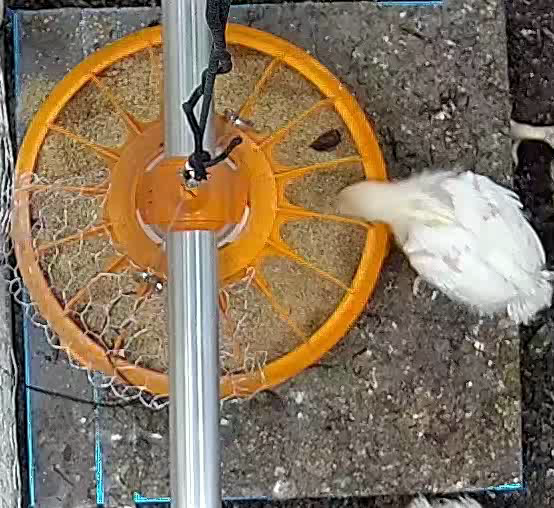

In [30]:
import csv
import sys
import subprocess
import cv2
from IPython.display import display, Image, Video

sys.path.insert(0, str(ROOT / 'src'))
from FeederCalibration import calibrate_pixel_to_cm
from Factories import AreaCalculatorFactory, AreaMethod, SegmenterFactory, SegmentationMethod
from ObjectFilterStrategy import SimpleObjectFilter
from compare_video import write_comparison
from scale_region import scale_mask_for_frame

def run_command(command):
    with subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1) as process:
        for line in process.stdout:
            print(line, end='', flush=True)
        if process.wait() != 0:
            raise subprocess.CalledProcessError(process.returncode, command)

metadata_path = EXPORT_DIR / 'test_videos' / 'metadata.csv'
events_path = EXPORT_DIR / 'ground_truth' / 'events.csv'
gt_path = EXPORT_DIR / 'ground_truth' / 'gt_boxes.csv'
for path in (metadata_path, events_path, gt_path):
    if not path.is_file():
        raise FileNotFoundError(f'Missing export file: {path}')
with metadata_path.open(newline='') as f:
    videos = list(csv.DictReader(f))
with events_path.open(newline='') as f:
    events = list(csv.DictReader(f))
with gt_path.open(newline='') as f:
    gt_rows = list(csv.DictReader(f))
if not videos or not gt_rows:
    raise ValueError('The export must contain at least one video and one ground-truth box.')
names = [row['video_name'] for row in videos]
missing_videos = [name for name in names if not (EXPORT_DIR / 'test_videos' / name).is_file()]
if missing_videos:
    raise FileNotFoundError(f'Videos listed in metadata but missing from export: {missing_videos}')
unknown_gt = sorted({row['video_name'] for row in gt_rows} - set(names))
if unknown_gt:
    raise ValueError(f'Ground-truth videos not listed in metadata: {unknown_gt}')
print(f'Export: {EXPORT_DIR}\nVideos: {len(videos)} | events: {len(events)} | GT boxes: {len(gt_rows)}')
display(videos[:5], events[:5], gt_rows[:5])
video_name = PREVIEW_VIDEO or names[0]
if video_name not in names:
    raise ValueError(f'Preview video is not in metadata: {video_name}')
video_path = EXPORT_DIR / 'test_videos' / video_name
if PREVIEW_FRAME < 1:
    raise ValueError('PREVIEW_FRAME must be one-based and at least 1')
cap = cv2.VideoCapture(str(video_path))
if not cap.isOpened():
    raise RuntimeError(f'Cannot open video: {video_path}')
try:
    cap.set(cv2.CAP_PROP_POS_FRAMES, PREVIEW_FRAME - 1)
    ok, frame = cap.read()
finally:
    cap.release()
if not ok:
    raise RuntimeError(f'Cannot read frame {PREVIEW_FRAME} from {video_path}')
def show_image(image):
    ok, encoded = cv2.imencode('.png', image)
    if not ok:
        raise RuntimeError('Could not encode preview image')
    display(Image(data=encoded.tobytes()))
print(f'Input: {video_name}, frame {PREVIEW_FRAME}, {frame.shape[1]} x {frame.shape[0]} pixels')
show_image(frame)

## Outline the weighing platform
In the setup cell, enter the corners of the square scale for each exported video in pixel coordinates, accounting for any export crop. Set `PREVIEW_VIDEO` to inspect each clip and rerun the load and outline cells. This is a fixed, manually annotated platform mask, not the orange feeder or an automatic detector. Check that the outline fits every frame. Overlap is only a visual proxy: a bird may overlap the platform without standing on it, or be occluded; review ambiguous and multiple-bird frames against the readings.

Weighing-platform mask and outline (yellow):


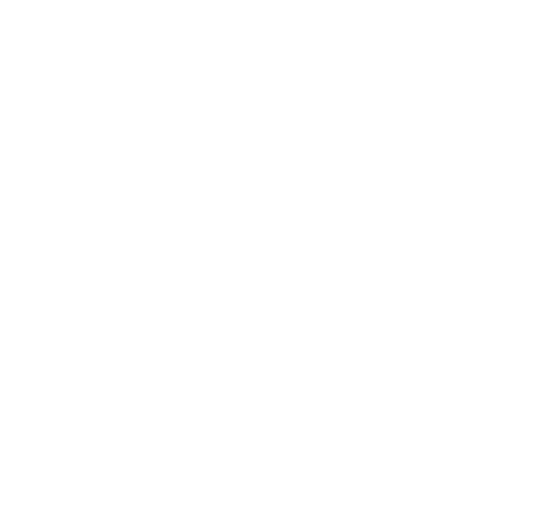

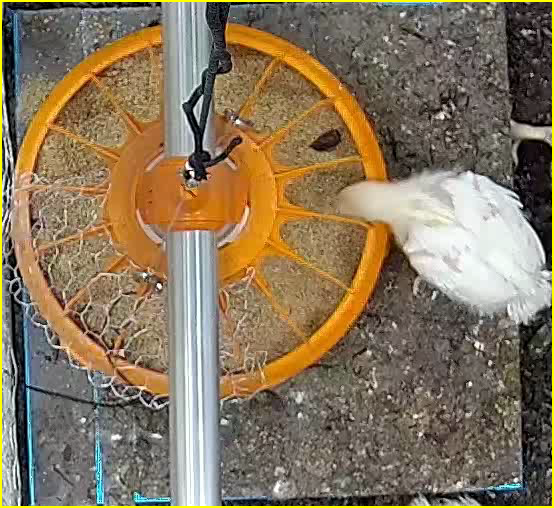

In [31]:
import numpy as np
if video_name not in SCALE_POLYGONS:
    raise ValueError(f'Add the square scale polygon for {video_name!r} to SCALE_POLYGONS in the setup cell.')
scale_mask = scale_mask_for_frame(SCALE_POLYGONS[video_name], frame.shape)
print('Weighing-platform mask and outline (yellow):')
show_image(scale_mask)
outlined = frame.copy()
cv2.polylines(outlined, [np.asarray(SCALE_POLYGONS[video_name], dtype=np.int32)], True, (0, 255, 255), 2)
show_image(outlined)

## 2. Calibrate pixel size
Use `pixel_to_cm` from the event if supplied; otherwise detect the orange feeder in the first frame. The scale converts pixel measurements into centimeters.

In [32]:
import math
event_by_video = {row['video_name']: row for row in events}
fixed_scale = event_by_video.get(video_name, {}).get('pixel_to_cm', '')
pixel_to_cm = float(fixed_scale) if fixed_scale else calibrate_pixel_to_cm(str(video_path))
if not math.isfinite(pixel_to_cm) or pixel_to_cm <= 0:
    raise ValueError(f'Invalid pixel_to_cm for {video_name}: {pixel_to_cm}')
print(f'{video_name}: {pixel_to_cm:.6f} cm/pixel ({"events.csv" if fixed_scale else "detected feeder"})')

[FeederCalibration] Feeder diameter: 385.3px -> pixel_to_cm=0.0923
v00008_20251001_165951.mp4: 0.092286 cm/pixel (detected feeder)


## 3. Segment foreground
The classical segmenter thresholds brightness, suppresses the orange feeder, and cleans the mask. White pixels are foreground candidates.

[ClassicalSegmenter] Initialized
Foreground pixels: 61,434 / 281,432


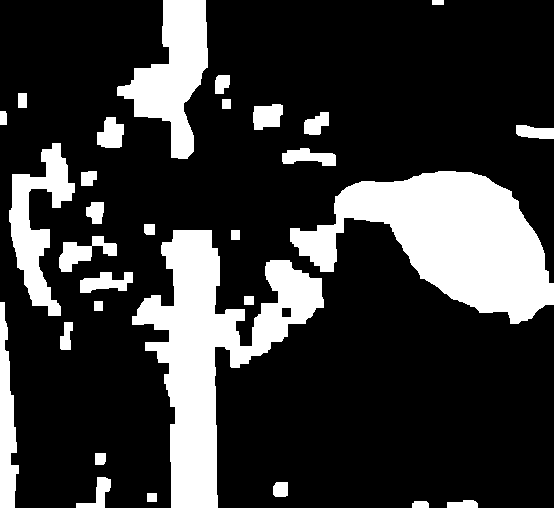

In [33]:
segmenter = SegmenterFactory().create(SegmentationMethod.CLASSICAL)
mask = segmenter.segment(frame)
print(f'Foreground pixels: {cv2.countNonZero(mask):,} / {mask.size:,}')
show_image(mask)

## 4. Filter candidates
Contours are checked for size and borders, then their filled, unrotated bird masks must overlap the scale by at least `MIN_SCALE_OVERLAP`. Candidates are checked for touching birds and template similarity before top-K selection. The cleaned mask includes contours before the scale test. For each selected candidate, the notebook displays its filled binary mask in the original orientation (white = bird), an overlay on the original frame, and the aligned mask used for estimation. The scale mask is not used to clip the bird.

Selected candidates: 0


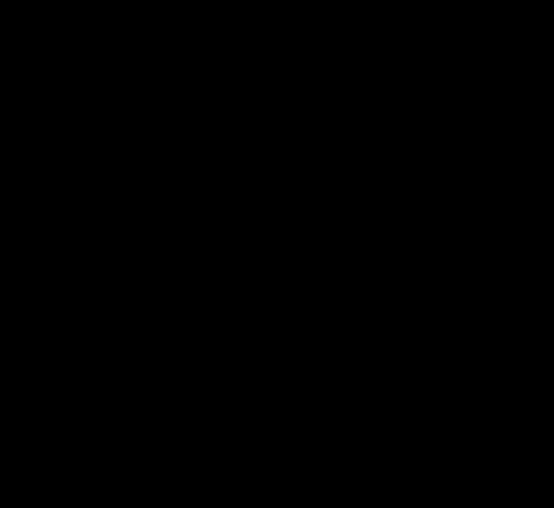

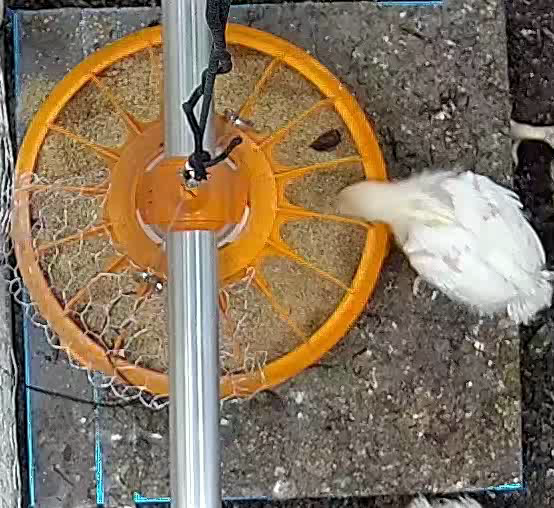

No bird mask passed selection on this frame. Try another PREVIEW_VIDEO or PREVIEW_FRAME and inspect the scale outline and foreground mask.


In [34]:
obj_filter = SimpleObjectFilter(target_labels=['Broiler'], template_mask=str(ROOT / 'src' / 'broiler_template.png'), min_area=500.0, scale_polygon=SCALE_POLYGONS[video_name], min_scale_overlap=MIN_SCALE_OVERLAP)
selected, clean_mask = obj_filter.should_process(mask)
print(f'Selected candidates: {len(selected)}')
show_image(clean_mask)
preview = frame.copy()
for obj in selected:
    x, y, w, h = obj.crop_region
    cv2.rectangle(preview, (x, y), (x+w, y+h), (0, 0, 255), 2)
show_image(preview)
if not selected:
    print('No bird mask passed selection on this frame. Try another PREVIEW_VIDEO or PREVIEW_FRAME and inspect the scale outline and foreground mask.')
for index, obj in enumerate(selected, 1):
    x, y, w, h = obj.crop_region
    print(f'Bird {index}, box {obj.crop_region}: unrotated filled mask (white = bird)')
    show_image(obj.source_mask)
    overlay = frame.copy()
    roi = overlay[y:y+h, x:x+w]
    green = np.zeros_like(roi)
    green[:] = (0, 255, 0)
    pixels = obj.source_mask > 0
    roi[pixels] = cv2.addWeighted(roi, 0.5, green, 0.5, 0)[pixels]
    print(f'Bird {index}: selected mask overlaid in green on the original frame')
    show_image(overlay)
    print(f'Bird {index}: aligned full-bird mask used for estimation')
    show_image(obj.mask)

## 5. Estimate weight
The filter rotates the full silhouette to its estimated body axis. The calculator treats its vertical span at each occupied column as the diameter of a circular cross-section. By default it sums one cylinder slice per column, converts cm³ to m³, and multiplies by density. This assumes circular cross-sections, not measured bird depth. A chosen slice count groups columns and samples each group's middle column. The output field `volume` is estimated mass in kg.

In [25]:
calculator = AreaCalculatorFactory().create(AreaMethod.CALIBRATED, pixel_to_cm=pixel_to_cm, broiler_density=DENSITY, slice_count=SLICE_COUNT)
preview_estimates = []
for obj in selected:
    obj = calculator.volume_from_mask(obj)
    preview_estimates.append({'box_xywh': obj.crop_region, 'estimated_weight_kg': obj.volume, 'score': obj.confidence_dt + obj.confidence_tpl})
display(preview_estimates)
if not preview_estimates:
    print('No candidate passed the filter in this preview frame; the full run may find birds in other frames.')

[]

No candidate passed the filter in this preview frame; the full run may find birds in other frames.


### Visualize the cylinder slices
For each selected, aligned mask, alternating colors show the column groups and yellow lines show the sampled vertical spans used as circular diameters. Each group's thickness is its occupied-column count times `pixel_to_cm`. The table lists the first 20 slices; the total includes every slice. These are geometric assumptions from a 2D silhouette, not observed 3D cross-sections. With `SLICE_COUNT = None` each occupied column is a slice, so the lines can appear dense; set a smaller count above and rerun the setup and preview cells to inspect coarser slices.

In [ ]:
from AreaCalculatorStrategy import mask_slice_profile
for index, obj in enumerate(selected, 1):
    profile = mask_slice_profile(obj.mask, SLICE_COUNT)
    groups = cv2.cvtColor(np.zeros_like(obj.mask), cv2.COLOR_GRAY2BGR)
    diameters = cv2.cvtColor((obj.mask > 0).astype(np.uint8) * 100, cv2.COLOR_GRAY2BGR)
    slice_rows = []
    for i, (start, end, sample, top, bottom, thickness) in enumerate(zip(
            profile['x_start'], profile['x_end'], profile['sample_x'], profile['y_min'],
            profile['y_max'], profile['thickness_px'])):
        region = groups[:, start:end+1]
        region[obj.mask[:, start:end+1] > 0] = (255, 140, 0) if i % 2 == 0 else (180, 0, 255)
        cv2.line(diameters, (int(sample), int(top)), (int(sample), int(bottom)), (0, 255, 255), 1)
        diameter_cm = int(bottom - top + 1) * pixel_to_cm
        thickness_cm = int(thickness) * pixel_to_cm
        volume_cm3 = math.pi * (diameter_cm / 2) ** 2 * thickness_cm
        slice_rows.append({'slice': i + 1, 'sample_column_px': int(sample), 'diameter_cm': diameter_cm,
                           'thickness_cm': thickness_cm, 'volume_cm3': volume_cm3})
    print(f'Bird {index}: {len(slice_rows)} slice groups (alternating colors)')
    show_image(groups)
    print('Sampled circular diameters (yellow) on aligned mask')
    show_image(diameters)
    display(slice_rows[:20])
    print(f'Total modeled volume: {sum(row["volume_cm3"] for row in slice_rows):.2f} cm³; estimated mass: {obj.volume:.4f} kg at {DENSITY:g} kg/m³')
if not selected:
    print('No selected bird masks to visualize on this frame.')

## Optional: explore slice counts and densities
Disabled by default, so Run All skips this potentially slow step. Set `RUN_TUNING = True` and provide disjoint event IDs as strings from `events.csv`: calibration IDs for selection and, preferably, held-out IDs for an unbiased check. Labeled frames are re-segmented with the same scale filter and IoU-matched one-to-one; unmatched events cause an error rather than disappearing silently. Candidates are ranked by calibration event-level RMSE using median frame estimates/readings. Only the selected candidate's held-out score is shown. This searches only the supplied grid, not a universal optimum; use independent recordings for the final assessment. To apply a result, manually set `DENSITY` and `SLICE_COUNT` above and rerun the preview and full pipeline.

In [ ]:
RUN_TUNING = False
CALIBRATION_EVENT_IDS = []  # e.g. ['1', '2']
HELD_OUT_EVENT_IDS = []  # e.g. ['3']; never use these to select parameters
SLICE_CANDIDATES = [None, 5, 10, 20, 40]
DENSITY_CANDIDATES = [700, 800, 900, 1000, 1100]
if RUN_TUNING:
    from collections import Counter
    from tune_validation import collect_matches, evaluate_grid
    matches = collect_matches(EXPORT_DIR, SCALE_POLYGONS, events, GT_FRAME_OFFSET, IOU_THRESHOLD, MIN_SCALE_OVERLAP)
    matched_counts = Counter(m[0] for m in matches)
    labeled_counts = Counter(row['event_id'] for row in gt_rows)
    print(f'Matched labeled boxes: {len(matches)} / {len(gt_rows)}; inspect per-event counts for selection bias:')
    display([{'event_id': event, 'matched': matched_counts[event], 'labeled': count} for event, count in sorted(labeled_counts.items())])
    grid = evaluate_grid(matches, CALIBRATION_EVENT_IDS, HELD_OUT_EVENT_IDS, SLICE_CANDIDATES, DENSITY_CANDIDATES)
    display([{k: v for k, v in row.items() if not k.startswith('held_out')} for row in grid])
    print('Held-out metrics for calibration-selected candidate:')
    display({k: v for k, v in grid[0].items() if k.startswith('held_out')})

## 6. Run every video
This calls the repository runner, using the same methods as the preview. It writes one results CSV and annotated video per clip. Existing files in the results directory are overwritten.

In [17]:
import json
if set(SCALE_POLYGONS) != set(names):
    raise ValueError(f'SCALE_POLYGONS must cover exactly all videos; missing: {sorted(set(names) - set(SCALE_POLYGONS))}, extra: {sorted(set(SCALE_POLYGONS) - set(names))}')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
polygon_path = RESULTS_DIR / 'scale_polygons.json'
polygon_path.write_text(json.dumps(SCALE_POLYGONS, indent=2))
command = [sys.executable, '-u', str(ROOT / 'src' / 'run_eval.py'), str(EXPORT_DIR), '--out', str(RESULTS_DIR), '--scale-polygons', str(polygon_path), '--min-scale-overlap', str(MIN_SCALE_OVERLAP), '--density', str(DENSITY)]
if SLICE_COUNT is not None:
    command += ['--slices', str(SLICE_COUNT)]
run_command(command)
for name in names:
    path = RESULTS_DIR / f'{Path(name).stem}_results.csv'
    with path.open(newline='') as f:
        rows = list(csv.DictReader(f))
    print(f'{name}: {len(rows)} estimates -> {path}')
    display(rows[:3])

[FeederCalibration] Feeder diameter: 3164.2px -> pixel_to_cm=0.0112
[calibration] v00008_20251001_165951.mp4: 0.0112381 cm/pixel
[ClassicalSegmenter] Initialized
[VideoProcessor] Start processing camera: v00008_20251001_165951
[VideoProcessor] End of video or cannot read frame.
[CSVOutputWriter] Saved results to /Users/akintanoreofeoluwa/Downloads/eval_2026-11-14_1552/results/v00008_20251001_165951_results.csv
[VideoProcessor] Finished camera: v00008_20251001_165951
[FeederCalibration] Feeder diameter: 3164.2px -> pixel_to_cm=0.0112
[calibration] v00010_20251001_165951.mp4: 0.0112381 cm/pixel
[ClassicalSegmenter] Initialized
[VideoProcessor] Start processing camera: v00010_20251001_165951
[VideoProcessor] End of video or cannot read frame.
[CSVOutputWriter] Saved results to /Users/akintanoreofeoluwa/Downloads/eval_2026-11-14_1552/results/v00010_20251001_165951_results.csv
[VideoProcessor] Finished camera: v00010_20251001_165951
[FeederCalibration] Feeder diameter: 2482.5px -> pixel_to_

[{'camera_id': 'v00008_20251001_165951',
  'frame_idx': '1',
  'label': 'broiler',
  'score': '1.1861020866582521',
  'volume': '0.0028256990432739258',
  'crop_region': '(2322, 762, 189, 186)'},
 {'camera_id': 'v00008_20251001_165951',
  'frame_idx': '1',
  'label': 'broiler',
  'score': '1.2237274370350235',
  'volume': '0.0019516842842102053',
  'crop_region': '(2109, 850, 253, 155)'},
 {'camera_id': 'v00008_20251001_165951',
  'frame_idx': '1',
  'label': 'broiler',
  'score': '1.2286878516765465',
  'volume': '0.005325937557220459',
  'crop_region': '(2197, 1179, 252, 278)'}]

v00010_20251001_165951.mp4: 3 estimates -> /Users/akintanoreofeoluwa/Downloads/eval_2026-11-14_1552/results/v00010_20251001_165951_results.csv


[{'camera_id': 'v00010_20251001_165951',
  'frame_idx': '1',
  'label': 'broiler',
  'score': '1.1861020866582521',
  'volume': '0.0028256990432739258',
  'crop_region': '(2322, 762, 189, 186)'},
 {'camera_id': 'v00010_20251001_165951',
  'frame_idx': '1',
  'label': 'broiler',
  'score': '1.2237274370350235',
  'volume': '0.0019516842842102053',
  'crop_region': '(2109, 850, 253, 155)'},
 {'camera_id': 'v00010_20251001_165951',
  'frame_idx': '1',
  'label': 'broiler',
  'score': '1.2286878516765465',
  'volume': '0.005325937557220459',
  'crop_region': '(2197, 1179, 252, 278)'}]

v00014_20251001_165955.mp4: 72 estimates -> /Users/akintanoreofeoluwa/Downloads/eval_2026-11-14_1552/results/v00014_20251001_165955_results.csv


[{'camera_id': 'v00014_20251001_165955',
  'frame_idx': '1',
  'label': 'broiler',
  'score': '1.3128246172661266',
  'volume': '0.0016398131132125855',
  'crop_region': '(2974, 178, 119, 104)'},
 {'camera_id': 'v00014_20251001_165955',
  'frame_idx': '1',
  'label': 'broiler',
  'score': '1.150601729146371',
  'volume': '0.005545249557495117',
  'crop_region': '(2320, 762, 190, 186)'},
 {'camera_id': 'v00014_20251001_165955',
  'frame_idx': '1',
  'label': 'broiler',
  'score': '1.2204119655102343',
  'volume': '0.010983640766143799',
  'crop_region': '(2198, 1179, 252, 276)'}]

v00016_20251001_165959.mp4: 53 estimates -> /Users/akintanoreofeoluwa/Downloads/eval_2026-11-14_1552/results/v00016_20251001_165959_results.csv


[{'camera_id': 'v00016_20251001_165959',
  'frame_idx': '1',
  'label': 'broiler',
  'score': '1.3180576374342556',
  'volume': '0.004640248632431031',
  'crop_region': '(2356, 770, 152, 194)'},
 {'camera_id': 'v00016_20251001_165959',
  'frame_idx': '1',
  'label': 'broiler',
  'score': '1.171767805302267',
  'volume': '0.0018140689373016357',
  'crop_region': '(890, 168, 166, 119)'},
 {'camera_id': 'v00016_20251001_165959',
  'frame_idx': '1',
  'label': 'broiler',
  'score': '1.2290722417185362',
  'volume': '0.011223437118530273',
  'crop_region': '(2198, 1179, 252, 283)'}]

## 7. Compare with ground truth
Boxes are greedily matched one-to-one within the same video and frame by intersection-over-union (IoU). The evaluator prints frame/event weight errors and detection rate. Estimates on frames without labels count as unmatched estimates, not necessarily confirmed false positives. Event actual weights use the median of matched scale readings. Density suggestions are exploratory; fit on separate calibration events and evaluate on held-out events.

In [18]:
eval_dir = RESULTS_DIR / 'evaluation'
run_command([sys.executable, '-u', str(ROOT / 'src' / 'evaluate_against_gt.py'), str(gt_path), '--results-dir', str(RESULTS_DIR), '--out', str(eval_dir), '--iou', str(IOU_THRESHOLD), '--gt-frame-offset', str(GT_FRAME_OFFSET), '--density', str(DENSITY)])
for name in ('matched.csv', 'per_event.csv'):
    with (eval_dir / name).open(newline='') as f:
        rows = list(csv.DictReader(f))
    print(f'{name}: {len(rows)} rows; first five:')
    display(rows[:5])

GT boxes: 8  estimates: 180
Matched: 4  detection rate: 50.0%  unmatched estimates: 176
Frame level  n=4  MAE=0.448 kg  RMSE=0.448 kg  bias=-0.448 kg  MAPE=99.5%
Event level  n=2/4  MAE=0.448 kg  RMSE=0.448 kg  bias=-0.448 kg  MAPE=99.5%
Density fit (event level, from 900 kg/m3): least-squares 183002 kg/m3, zero-bias 185131 kg/m3. Fit on a calibration subset and report error on held-out events.
matched.csv: 4 rows; first five:


[{'video_name': 'v00008_20251001_165951.mp4',
  'frame_idx': '1',
  'volume': '0.0019516842842102053',
  'score': '1.2237274370350235',
  'crop_region': '(2109, 850, 253, 155)',
  'iou': '0.579',
  'actual_weight_kg': '0.45',
  'event_id': '8'},
 {'video_name': 'v00008_20251001_165951.mp4',
  'frame_idx': '13',
  'volume': '0.0024235990047454838',
  'score': '1.1942421087859372',
  'crop_region': '(2099, 845, 258, 154)',
  'iou': '0.633',
  'actual_weight_kg': '0.45',
  'event_id': '8'},
 {'video_name': 'v00008_20251001_165951.mp4',
  'frame_idx': '18',
  'volume': '0.002429978799819946',
  'score': '1.1939398545832607',
  'crop_region': '(2099, 847, 259, 154)',
  'iou': '0.551',
  'actual_weight_kg': '0.45',
  'event_id': '8'},
 {'video_name': 'v00010_20251001_165951.mp4',
  'frame_idx': '1',
  'volume': '0.0019516842842102053',
  'score': '1.2237274370350235',
  'crop_region': '(2109, 850, 253, 155)',
  'iou': '0.74',
  'actual_weight_kg': '0.45',
  'event_id': '10'}]

per_event.csv: 2 rows; first five:


[{'event_id': '10',
  'actual_weight_kg': '0.45',
  'median_estimate_kg': '0.002',
  'n_frames_matched': '1',
  'iqr_kg': '0.0'},
 {'event_id': '8',
  'actual_weight_kg': '0.45',
  'median_estimate_kg': '0.0024',
  'n_frames_matched': '3',
  'iqr_kg': '0.0005'}]

## 8. Watch true vs estimated boxes
Green = ground truth and red = pipeline estimate; labels show weights. All boxes are shown, not just IoU matches. Frames without annotations have no green box. The first video with ground truth is displayed; comparison videos for all labeled clips are saved in `results/comparisons`. If your browser cannot play the OpenCV MP4 codec, open the saved file in a local video player.

In [19]:
comparison_dir = RESULTS_DIR / 'comparisons'
comparisons = []
for name in sorted({row['video_name'] for row in gt_rows}):
    output = comparison_dir / f'{Path(name).stem}_comparison.mp4'
    write_comparison(EXPORT_DIR / 'test_videos' / name, gt_path, RESULTS_DIR / f'{Path(name).stem}_results.csv', output, GT_FRAME_OFFSET, video_name=name)
    comparisons.append(output)
    print(f'Saved: {output}')
print(f'Displaying {comparisons[0].name} (embedding large videos may take time).')
display(Video(str(comparisons[0]), embed=True))

Saved: /Users/akintanoreofeoluwa/Downloads/eval_2026-11-14_1552/results/comparisons/v00008_20251001_165951_comparison.mp4
Saved: /Users/akintanoreofeoluwa/Downloads/eval_2026-11-14_1552/results/comparisons/v00010_20251001_165951_comparison.mp4
Saved: /Users/akintanoreofeoluwa/Downloads/eval_2026-11-14_1552/results/comparisons/v00014_20251001_165955_comparison.mp4
Saved: /Users/akintanoreofeoluwa/Downloads/eval_2026-11-14_1552/results/comparisons/v00016_20251001_165959_comparison.mp4
Displaying v00008_20251001_165951_comparison.mp4 (embedding large videos may take time).
